# Purpose
The purpose of this notebook is to fully analyze the cleaned and filtered faculty data parquet file. 

Please run the filter_and_sort.ipynb to obtain the parquet file. Alternatively get the data from  [Google Drive](https://drive.google.com/drive/folders/1JIC3yfQ-2-siGTgWW8LAvi-2jwqDDESW?usp=drive_link)

## Load Data

In [31]:
import polars as pl
import duckdb
import matplotlib.pyplot as plt
import seaborn as sns

df = pl.read_parquet("data/csu_depbucket_cleaned_salaries.parquet")
duckdb.connect()

duckdb.sql(f"""
CREATE OR REPLACE TABLE faculty_salaries AS
    SELECT *
    FROM df
    """)

## General Faculty EDA

In [32]:
df.describe()

statistic,year_transparentCA,school,name,title,original_department,department,total_pay,base_pay,overtime_pay,other_pay
str,f64,str,str,str,str,str,f64,f64,f64,f64
"""count""",7397.0,"""7397""","""7397""","""7397""","""7276""","""7397""",7397.0,7397.0,7397.0,7397.0
"""null_count""",0.0,"""0""","""0""","""0""","""121""","""0""",0.0,0.0,0.0,0.0
"""mean""",2024.0,null,null,null,null,null,113188.25497,102848.602335,2.627219,10337.025416
"""std""",0.0,null,null,null,null,null,39439.287922,33681.023239,169.574933,14081.189577
"""min""",2024.0,"""CSU Bakersfield""","""Aaminah Norris""","""Adjunct""","""""","""Agriculture, Food & Animal""",35244.14,35169.34,0.0,-7345.7
"""25%""",2024.0,null,null,null,null,null,87033.48,79992.23,0.0,0.0
"""50%""",2024.0,null,null,null,null,null,113013.2,104508.84,0.0,5591.2
"""75%""",2024.0,null,null,null,null,null,135643.92,124700.0,0.0,14750.0
"""max""",2024.0,"""Sonoma State University""","""Zuzana Janko""","""Undergraduate Mentor & Associa…","""the School of Journalism and M…","""Social Sciences & Communicatio…",365885.88,365885.88,13642.82,158025.49


In [46]:
single_person_departments_by_school = duckdb.sql("""
WITH department_counts AS (
    SELECT
        year_transparentCA AS year,
        school,
        lower(trim(original_department)) AS original_department,
        COUNT(DISTINCT lower(trim(name))) AS people
    FROM faculty_salaries
    WHERE original_department IS NOT NULL
      AND trim(original_department) <> ''
    GROUP BY year_transparentCA, school, lower(trim(original_department))
),

school_counts AS (
    SELECT
        year,
        school,
        COUNT(*) FILTER (WHERE people = 1) AS single_person_departments,
        COUNT(*) AS total_departments,
        ROUND(
            100.0 * COUNT(*) FILTER (WHERE people = 1) / COUNT(*), 1
        ) AS single_person_pct
    FROM department_counts
    GROUP BY year, school
),

ranked_schools AS (
    SELECT *,
        ROW_NUMBER() OVER (
            PARTITION BY year
            ORDER BY single_person_departments DESC,
                     single_person_pct DESC,
                     school
        ) AS rank
    FROM school_counts
),

top_school_departments AS (
    SELECT
        d.year,
        d.school,
        LIST(d.original_department ORDER BY d.original_department)
            FILTER (WHERE d.people = 1)[:10] AS example_single_person_departments
    FROM department_counts d
    JOIN ranked_schools r
        ON d.year = r.year
       AND d.school = r.school
    WHERE r.rank <= 23
    GROUP BY d.year, d.school
)

SELECT
    r.year,
    r.school,
    r.single_person_departments,
    r.total_departments,
    r.single_person_pct,
    CASE
        WHEN r.rank <= 23 THEN t.example_single_person_departments
        ELSE NULL
    END AS example_single_person_departments
FROM ranked_schools r
LEFT JOIN top_school_departments t
    ON r.year = t.year
   AND r.school = t.school
ORDER BY
    r.year DESC,
    r.single_person_departments DESC,
    r.single_person_pct DESC,
    r.school
""").pl()

with pl.Config(tbl_rows=-1, fmt_str_lengths=100):
    display(single_person_departments_by_school)

year,school,single_person_departments,total_departments,single_person_pct,example_single_person_departments
i64,str,i64,i64,f64,list[str]
2024,"""California State University, Sacramento""",65,122,53.3,"[""accountancy, department chair - accounting"", ""biological sciences; chair, department of biological sciences"", … ""construction management; chair, department of construction management""]"
2024,"""San Diego State University""",64,137,46.7,"[""abd, comparative international studies, italian"", ""american indian studies, m.a., higher education"", … ""chinese""]"
2024,"""Cal Poly Pomona""",38,88,43.2,"[""[academic department]"", ""accounting department"", … ""chemical & materials engineering department""]"
2024,"""San Jose State University""",28,60,46.7,"[""aerospace engineering"", ""american studies"", … ""education""]"
2024,"""California State University, Dominguez Hills""",28,61,45.9,"[""accounting"", ""accounting and finance"", … ""communications""]"
2024,"""California State University, Chico""",19,60,31.7,"[""anthropology; social science"", ""art & art history; computer animation & game devl"", … ""info systems, finance&account; management""]"
2024,"""California State University San Marcos""",18,53,34.0,"[""arts, media and design"", ""chemistry & biochemistry"", … ""global studies & political science""]"
2024,"""CSU Channel Islands""",16,28,57.1,"[""black studies"", ""comp sci"", … ""marketing""]"
2024,"""San Francisco State University""",13,75,17.3,"[""american indian studies"", ""biomedical laboratory science"", … ""labor and employment studies""]"


In [34]:
# Entry counts and distinct original department names within each bucket.
# Entries count rows, including preserved multiple affiliations.
# Department names are counted across schools, ignoring case and outer spaces;
# null/blank names are excluded from department counts but included in entries.
bucket_counts = duckdb.sql("""
SELECT
    department AS department_bucket,
    COUNT(*) AS entry_count,
    COUNT(DISTINCT NULLIF(lower(trim(original_department)), ''))
        AS distinct_departments
FROM faculty_salaries
GROUP BY department
ORDER BY entry_count DESC, department_bucket
""").pl()

with pl.Config(tbl_rows=-1, fmt_str_lengths=60):
    display(bucket_counts)


department_bucket,entry_count,distinct_departments
str,i64,i64
"""Humanities & Languages""",1578,165
"""Social Sciences & Communication""",1482,111
"""Science & Mathematics""",1075,51
"""Business, Economics & Finance""",859,78
"""Education & Public Administration""",569,77
"""Medicine & Health Sciences""",498,39
"""Computer Science""",395,42
"""Engineering""",342,47
"""Agriculture, Food & Animal""",235,28


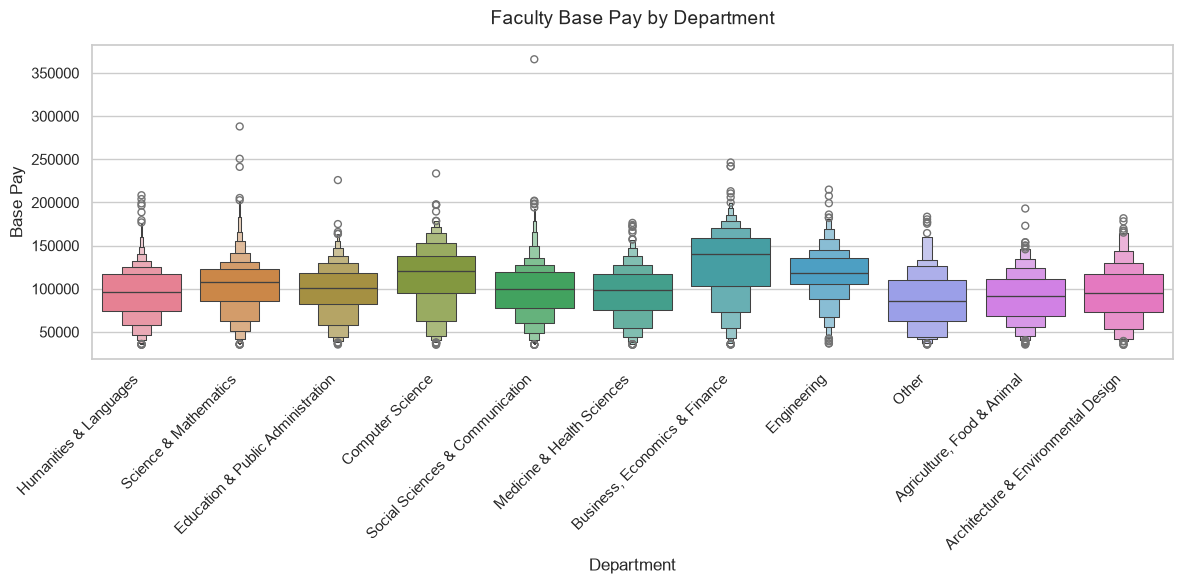

In [35]:
pay_by_salary = duckdb.sql("""
SELECT total_pay, base_pay, department
FROM faculty_salaries
""").pl()

sns.set_theme(style="whitegrid")
plt.figure(figsize=(12, 6))

sns.boxenplot(
    data=pay_by_salary.to_pandas(), 
    x="department",
    y='base_pay',
    hue="department"
)

plt.title("Faculty Base Pay by Department", fontsize=14, pad=15)
plt.xlabel("Department", fontsize=12)
plt.ylabel("Base Pay", fontsize=12)

plt.xticks(rotation=45, ha='right')

plt.tight_layout()
plt.show()

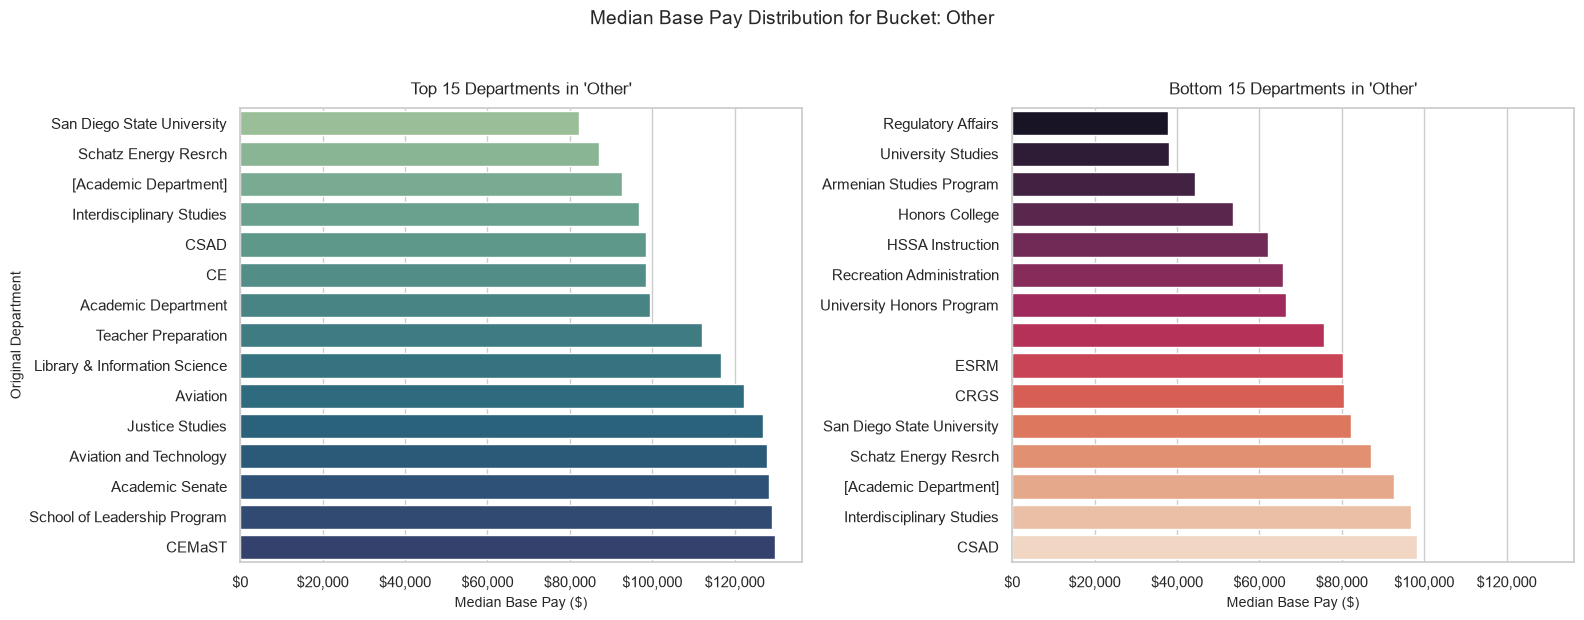

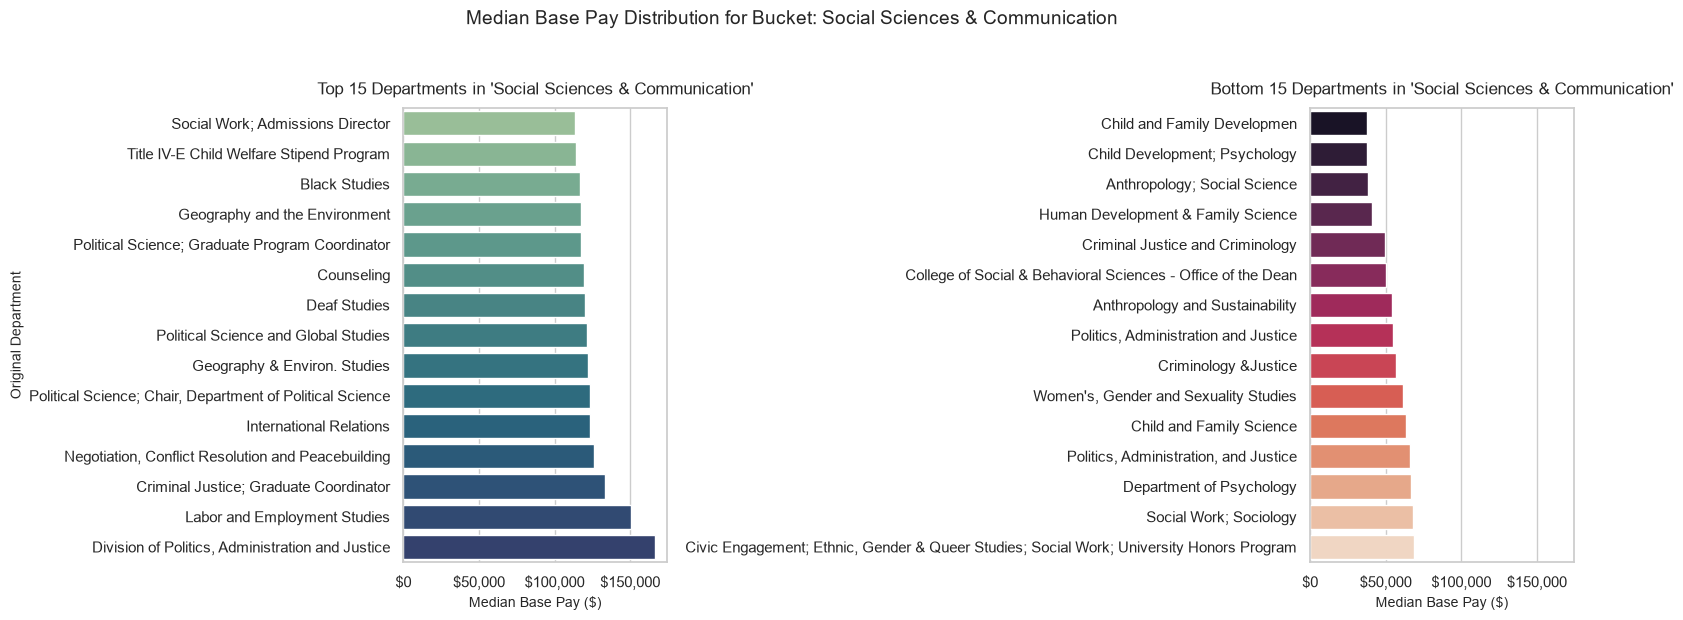

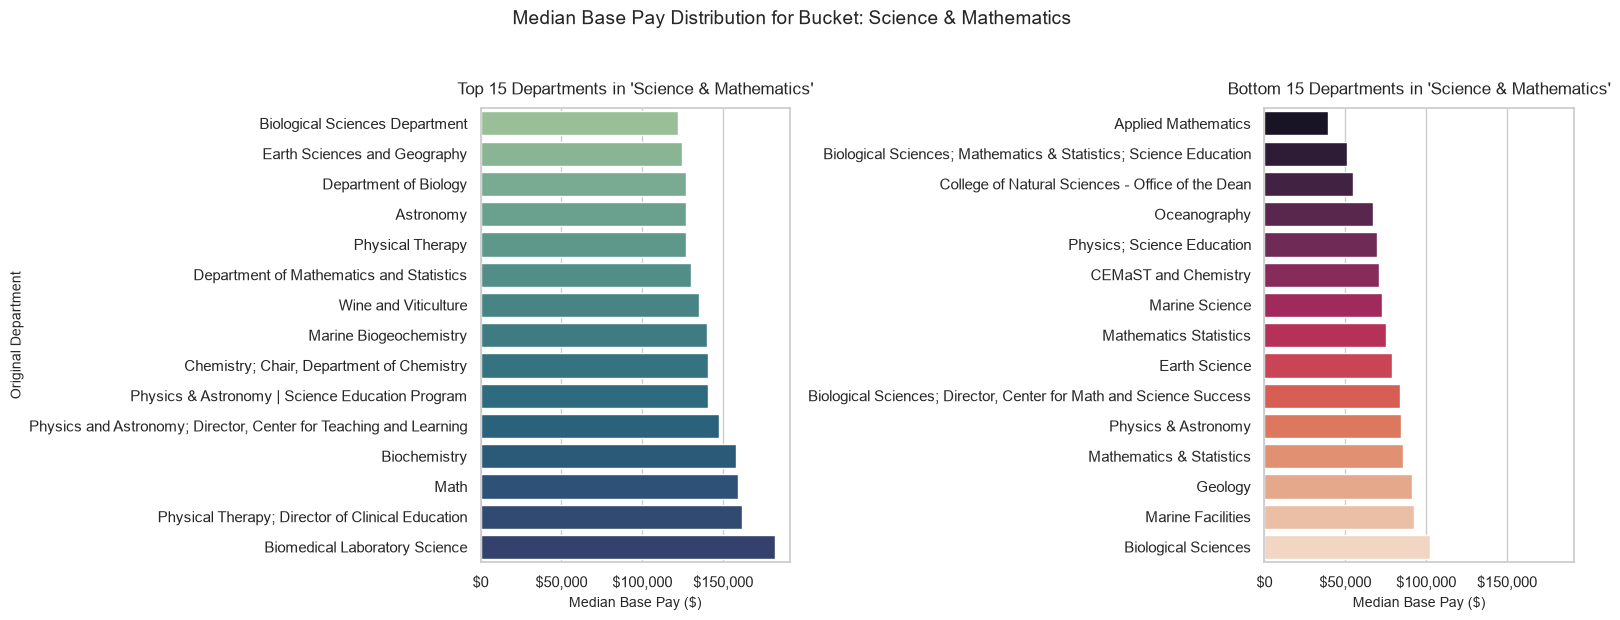

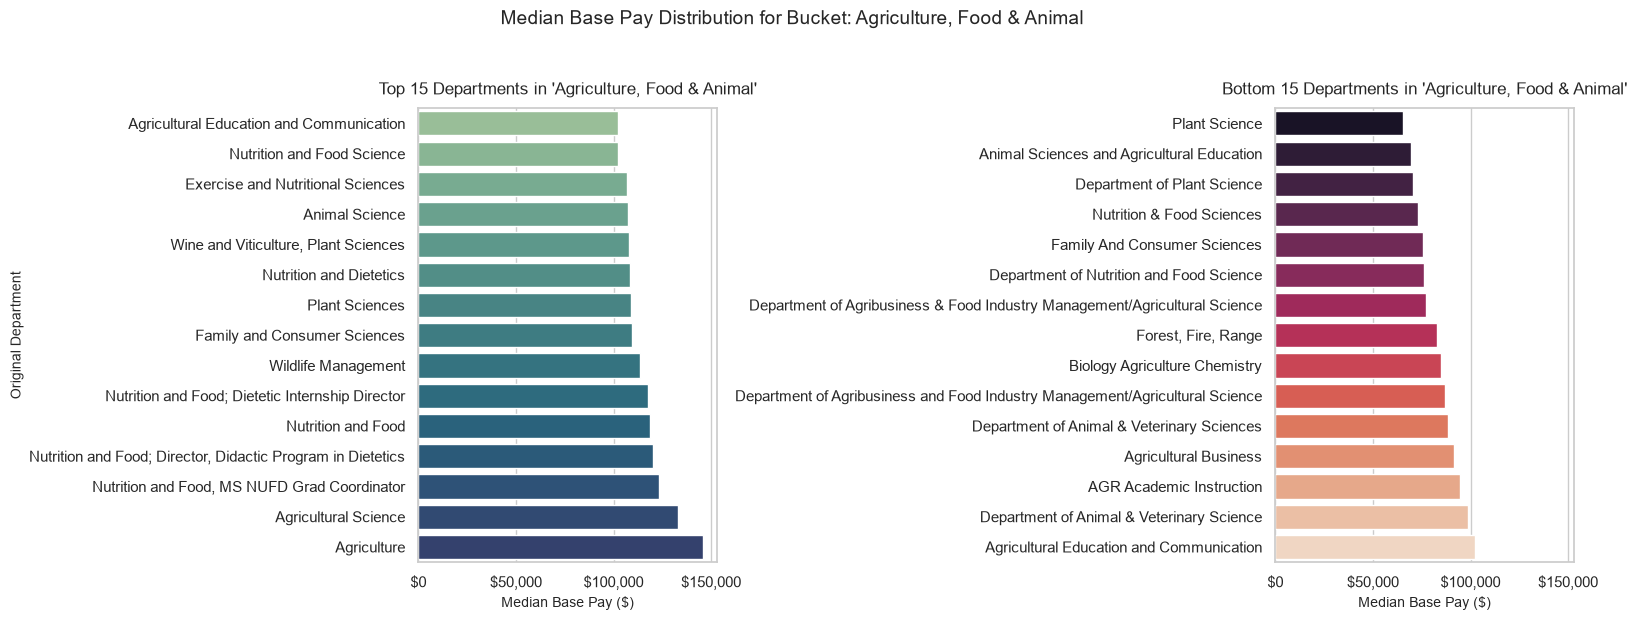

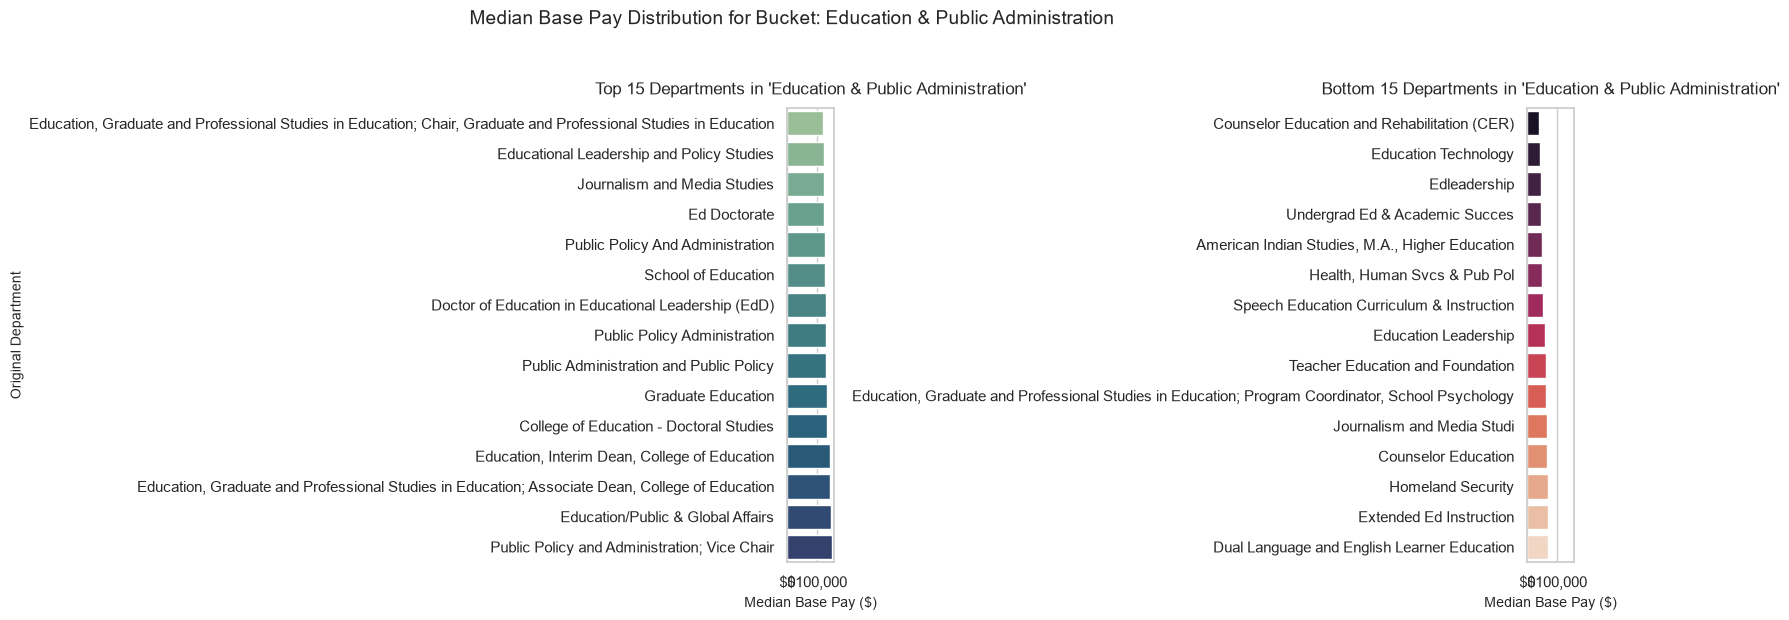

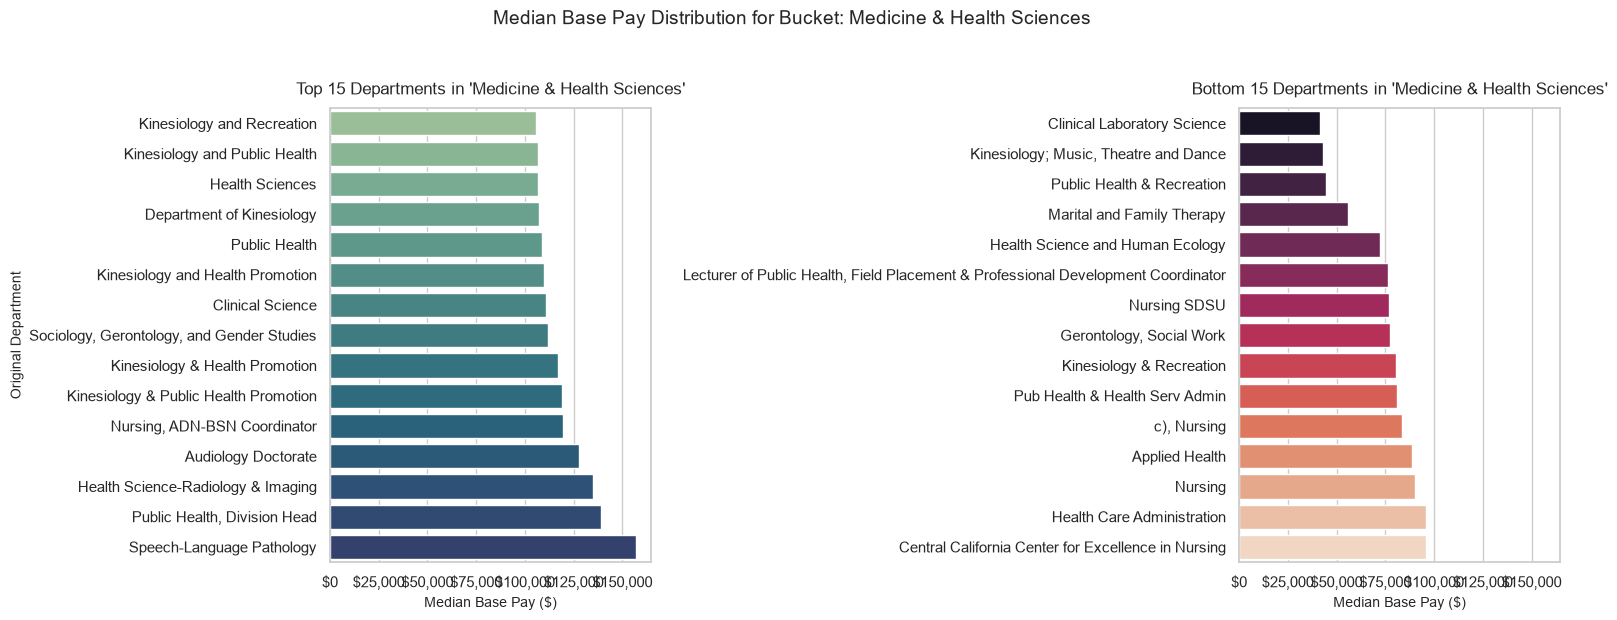

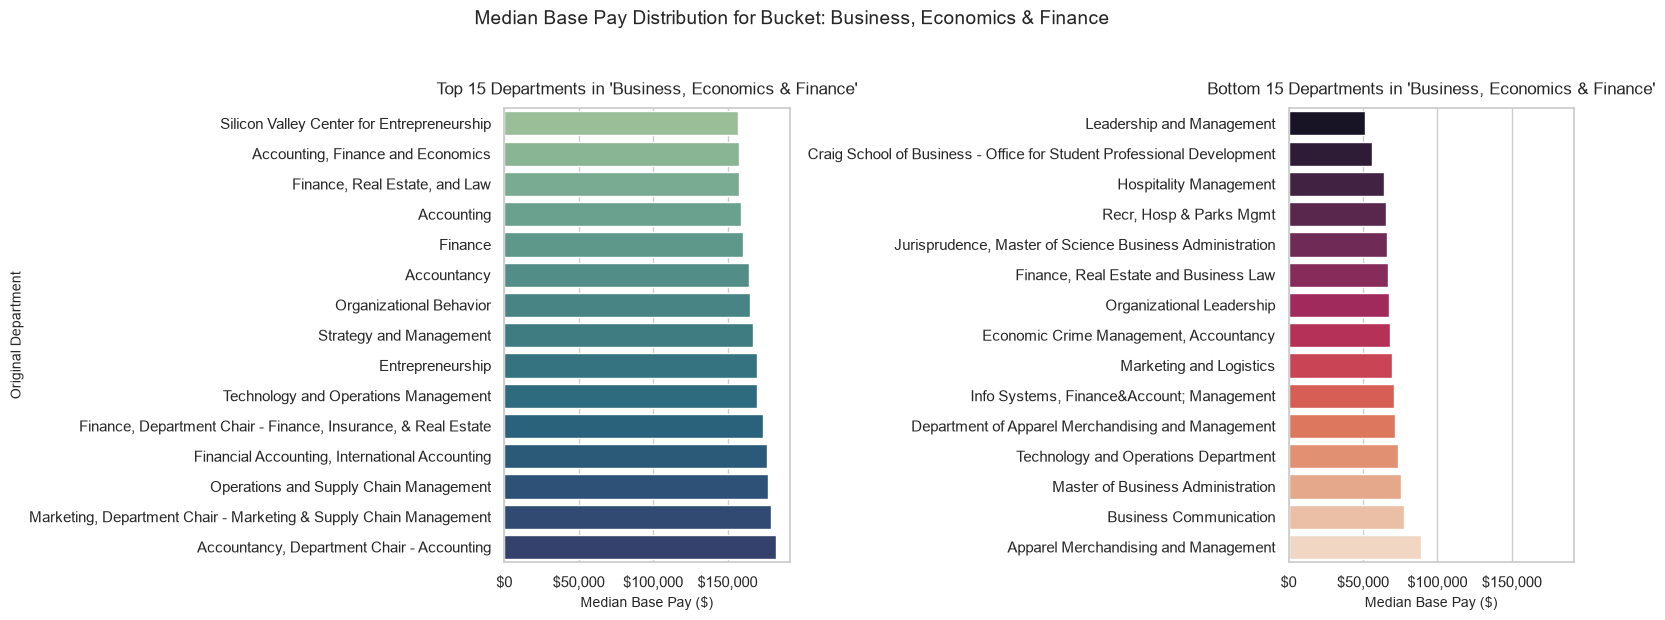

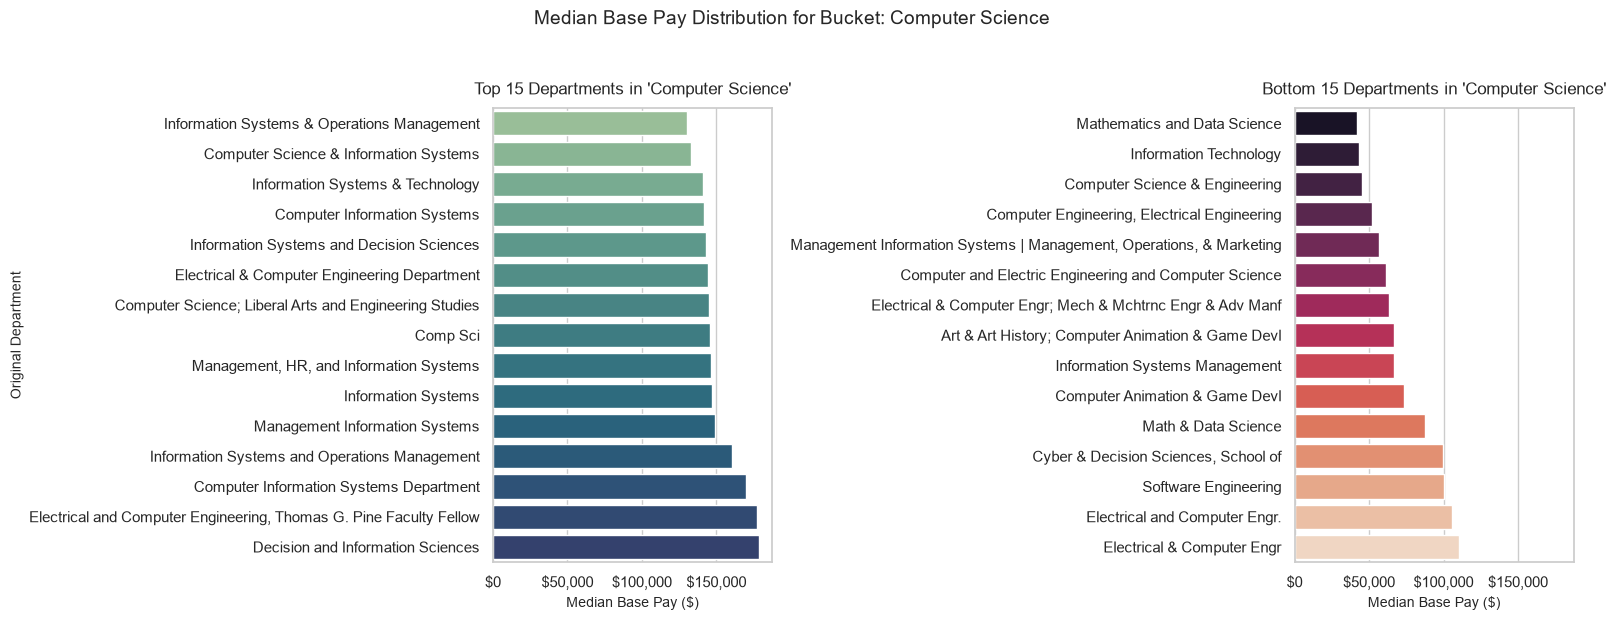

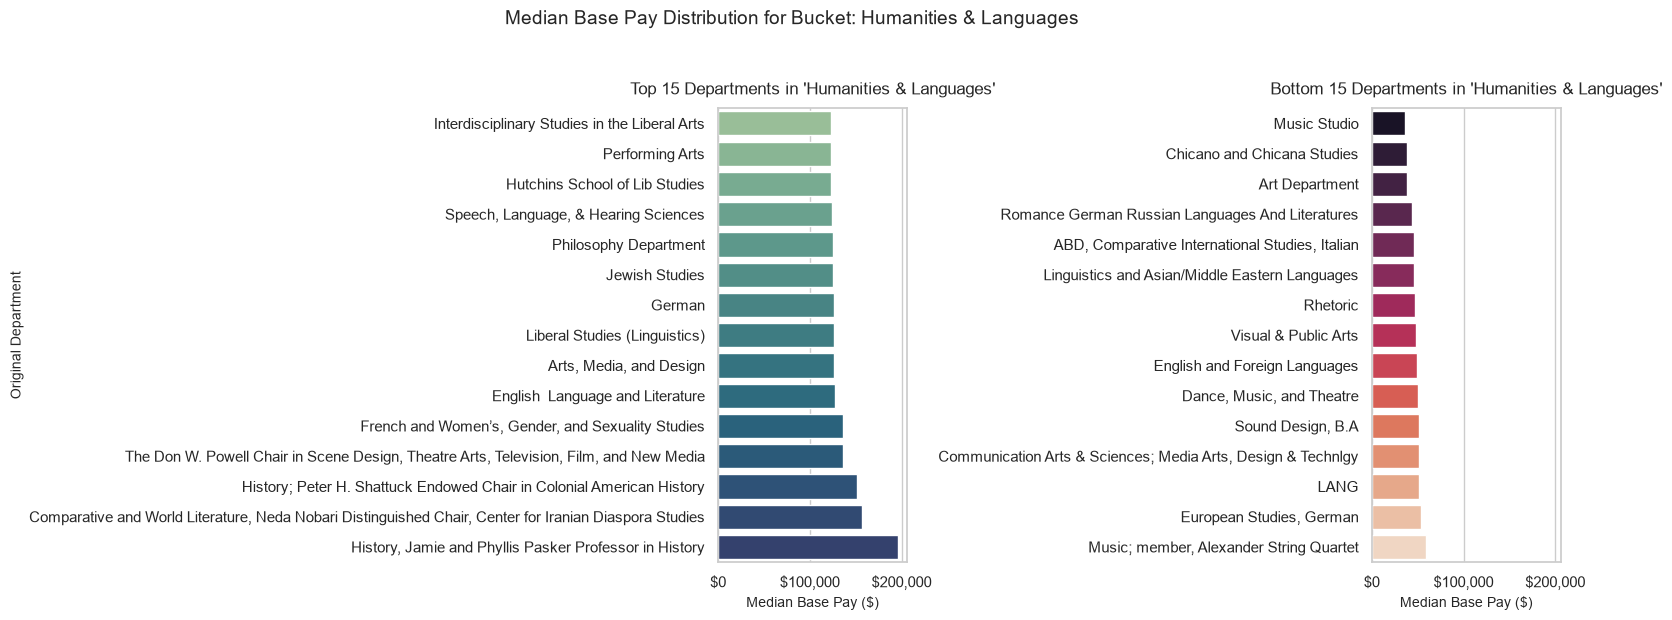

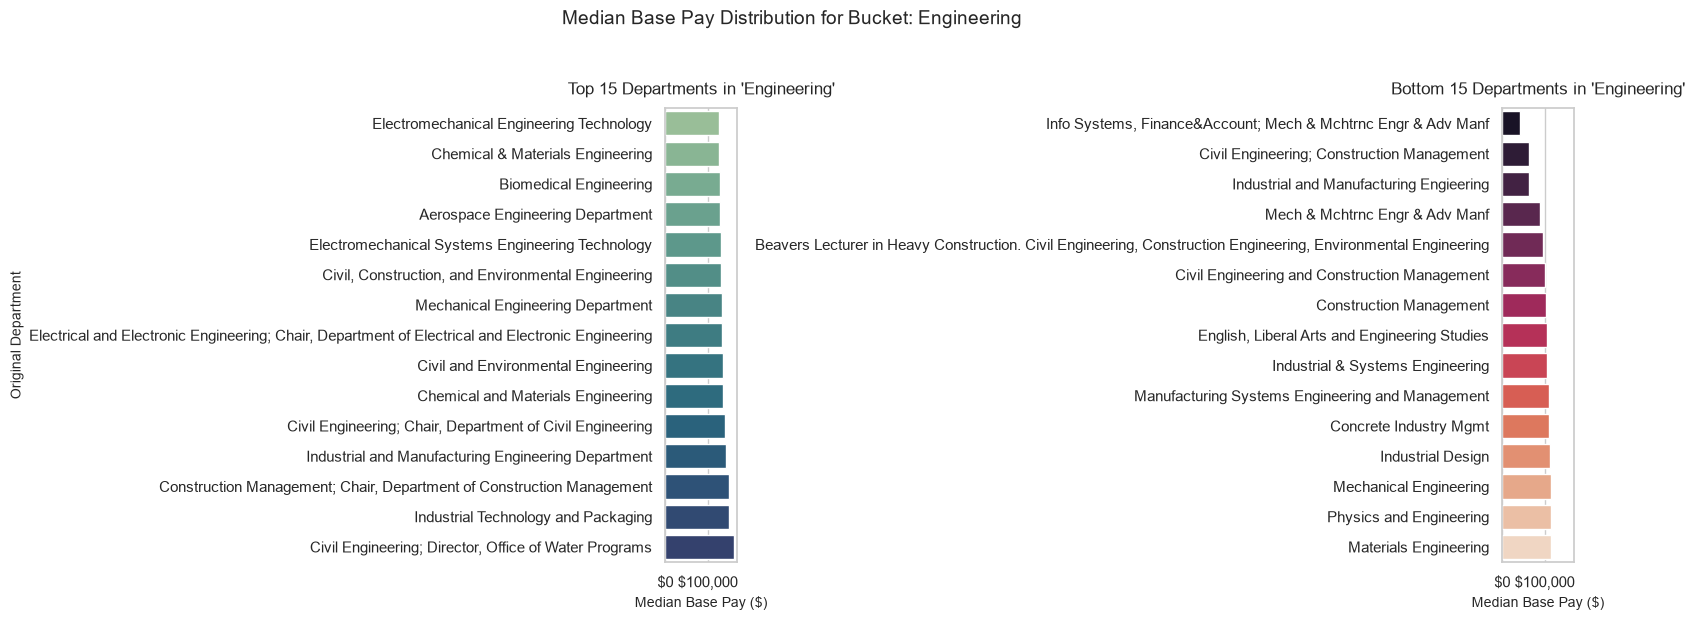

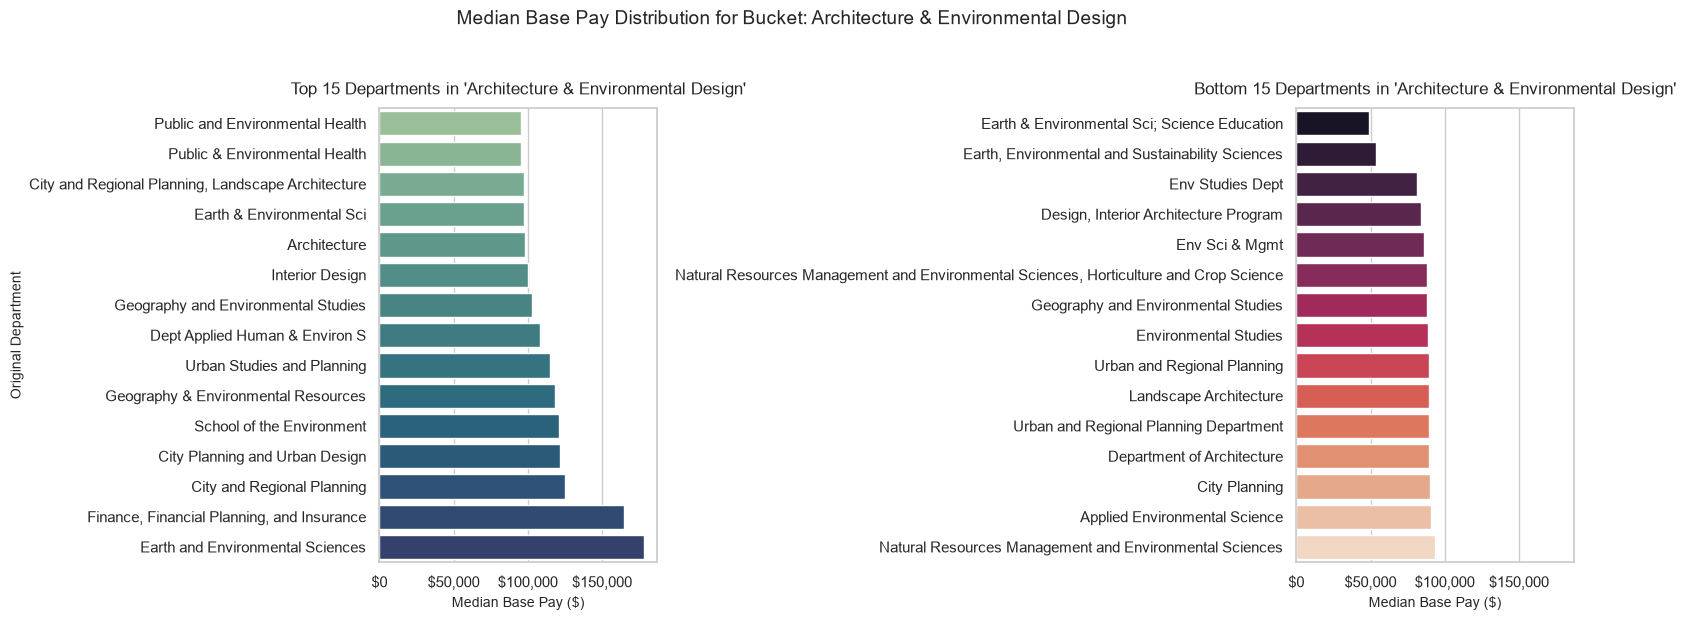

In [36]:
# Graph Generated by Gemni Flash-Lite 2.5

import duckdb
import matplotlib.pyplot as plt
import polars as pl
import seaborn as sns

# 1. Load data using Polars
df = pl.read_parquet("data/csu_depbucket_cleaned_salaries.parquet")

# 2. Register with DuckDB for fast aggregation
con = duckdb.connect()
con.register("faculty", df)

# 3. Calculate median base pay for each original department within each bucket
dept_summary = con.execute("""
    SELECT 
        department AS dep_bucket,
        original_department,
        MEDIAN(base_pay) AS median_base_pay,
        COUNT(*) as faculty_count
    FROM faculty
    WHERE original_department IS NOT NULL
    GROUP BY department, original_department
    ORDER BY department, median_base_pay DESC
""").pl()

# Set visual style
sns.set_theme(style="whitegrid")

# 4. Iterate through each department bucket and plot top & bottom 15
buckets = dept_summary["dep_bucket"].unique().to_list()

for bucket in buckets:
  # Filter data for the specific bucket
  subset = dept_summary.filter(pl.col("dep_bucket") == bucket)

  # If a bucket has fewer than 30 departments, adjust accordingly
  total_count = len(subset)
  if total_count < 5:
    continue  # Skip buckets that are too small to split meaningfully

  # Sort descending for top, ascending for bottom
  top_depts = subset.head(15).sort("median_base_pay", descending=False)
  bottom_depts = subset.tail(15).sort("median_base_pay", descending=False)

  # Create a figure with 2 subplots (Top 15 and Bottom 15)
  fig, axes = plt.subplots(1, 2, figsize=(16, 6), sharex=True)

  # Plot Top 15
  sns.barplot(
      data=top_depts.to_pandas(),
      x="median_base_pay",
      y="original_department",
      palette="crest",
      ax=axes[0],
      hue="original_department",
      legend=False,
  )
  axes[0].set_title(
      f"Top {len(top_depts)} Departments in '{bucket}'", fontsize=12, pad=10
  )
  axes[0].set_xlabel("Median Base Pay ($)", fontsize=10)
  axes[0].set_ylabel("Original Department", fontsize=10)
  axes[0].xaxis.set_major_formatter(
      plt.FuncFormatter(lambda x, loc: f"${int(x):,}")
  )

  # Plot Bottom 15
  sns.barplot(
      data=bottom_depts.to_pandas(),
      x="median_base_pay",
      y="original_department",
      palette="rocket",
      ax=axes[1],
      hue="original_department",
      legend=False,
  )
  axes[1].set_title(
      f"Bottom {len(bottom_depts)} Departments in '{bucket}'",
      fontsize=12,
      pad=10,
  )
  axes[1].set_xlabel("Median Base Pay ($)", fontsize=10)
  axes[1].set_ylabel("")
  axes[1].xaxis.set_major_formatter(
      plt.FuncFormatter(lambda x, loc: f"${int(x):,}")
  )

  plt.suptitle(
      f"Median Base Pay Distribution for Bucket: {bucket}",
      fontsize=14,
      y=1.03,
  )
  plt.tight_layout()

  safe_name = bucket.lower().replace(" & ", "_").replace(" ", "_")
#   plt.savefig(f"data/bucket_top_bottom_{safe_name}.png", dpi=300, bbox_inches="tight")
  plt.show()

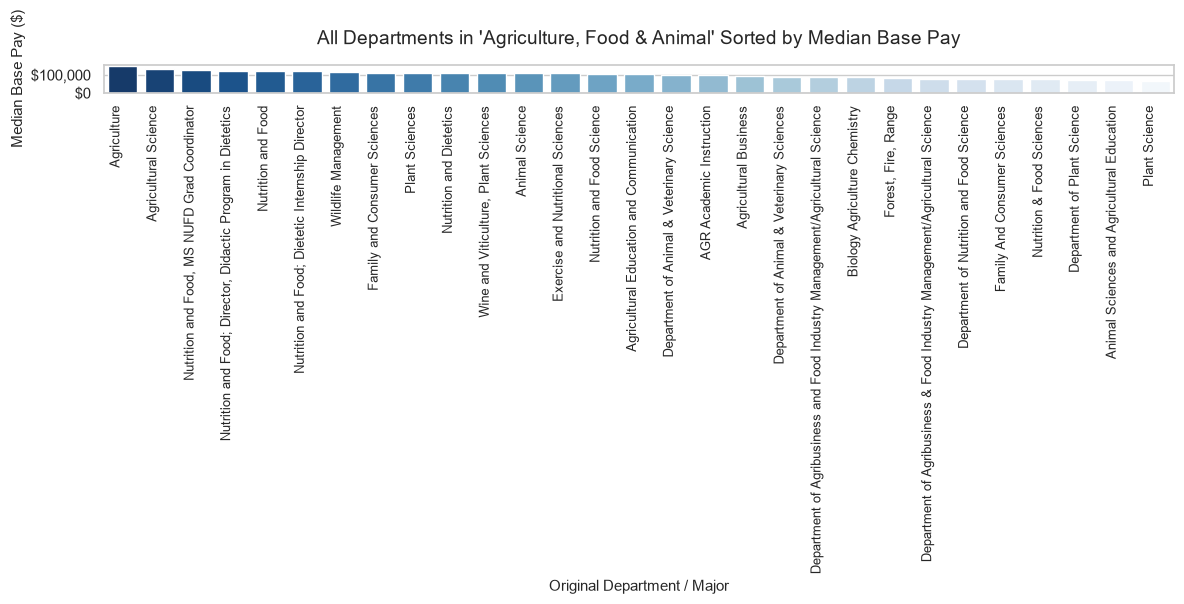

C:\Users\ginny\AppData\Local\Temp\ipykernel_26268\20446149.py:56: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


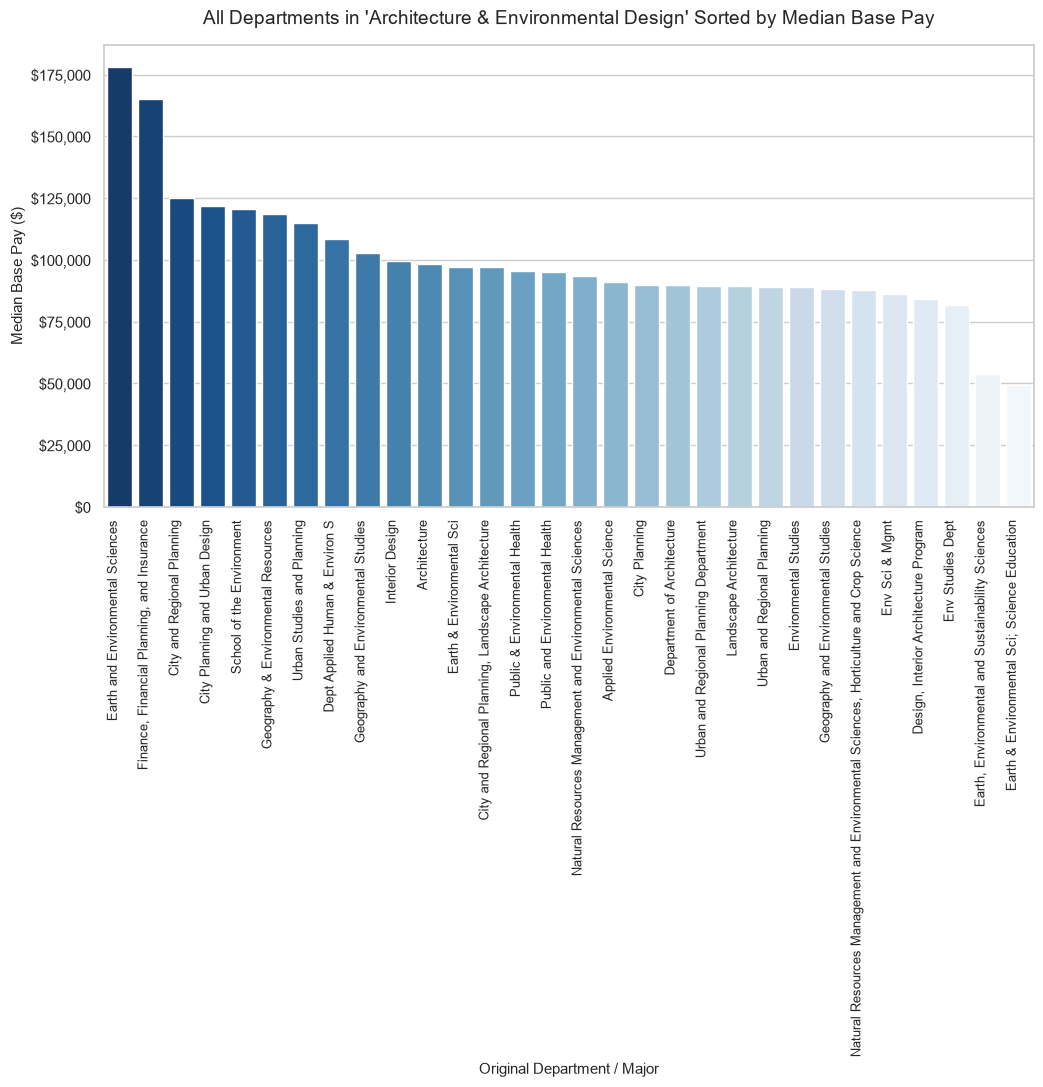

C:\Users\ginny\AppData\Local\Temp\ipykernel_26268\20446149.py:56: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


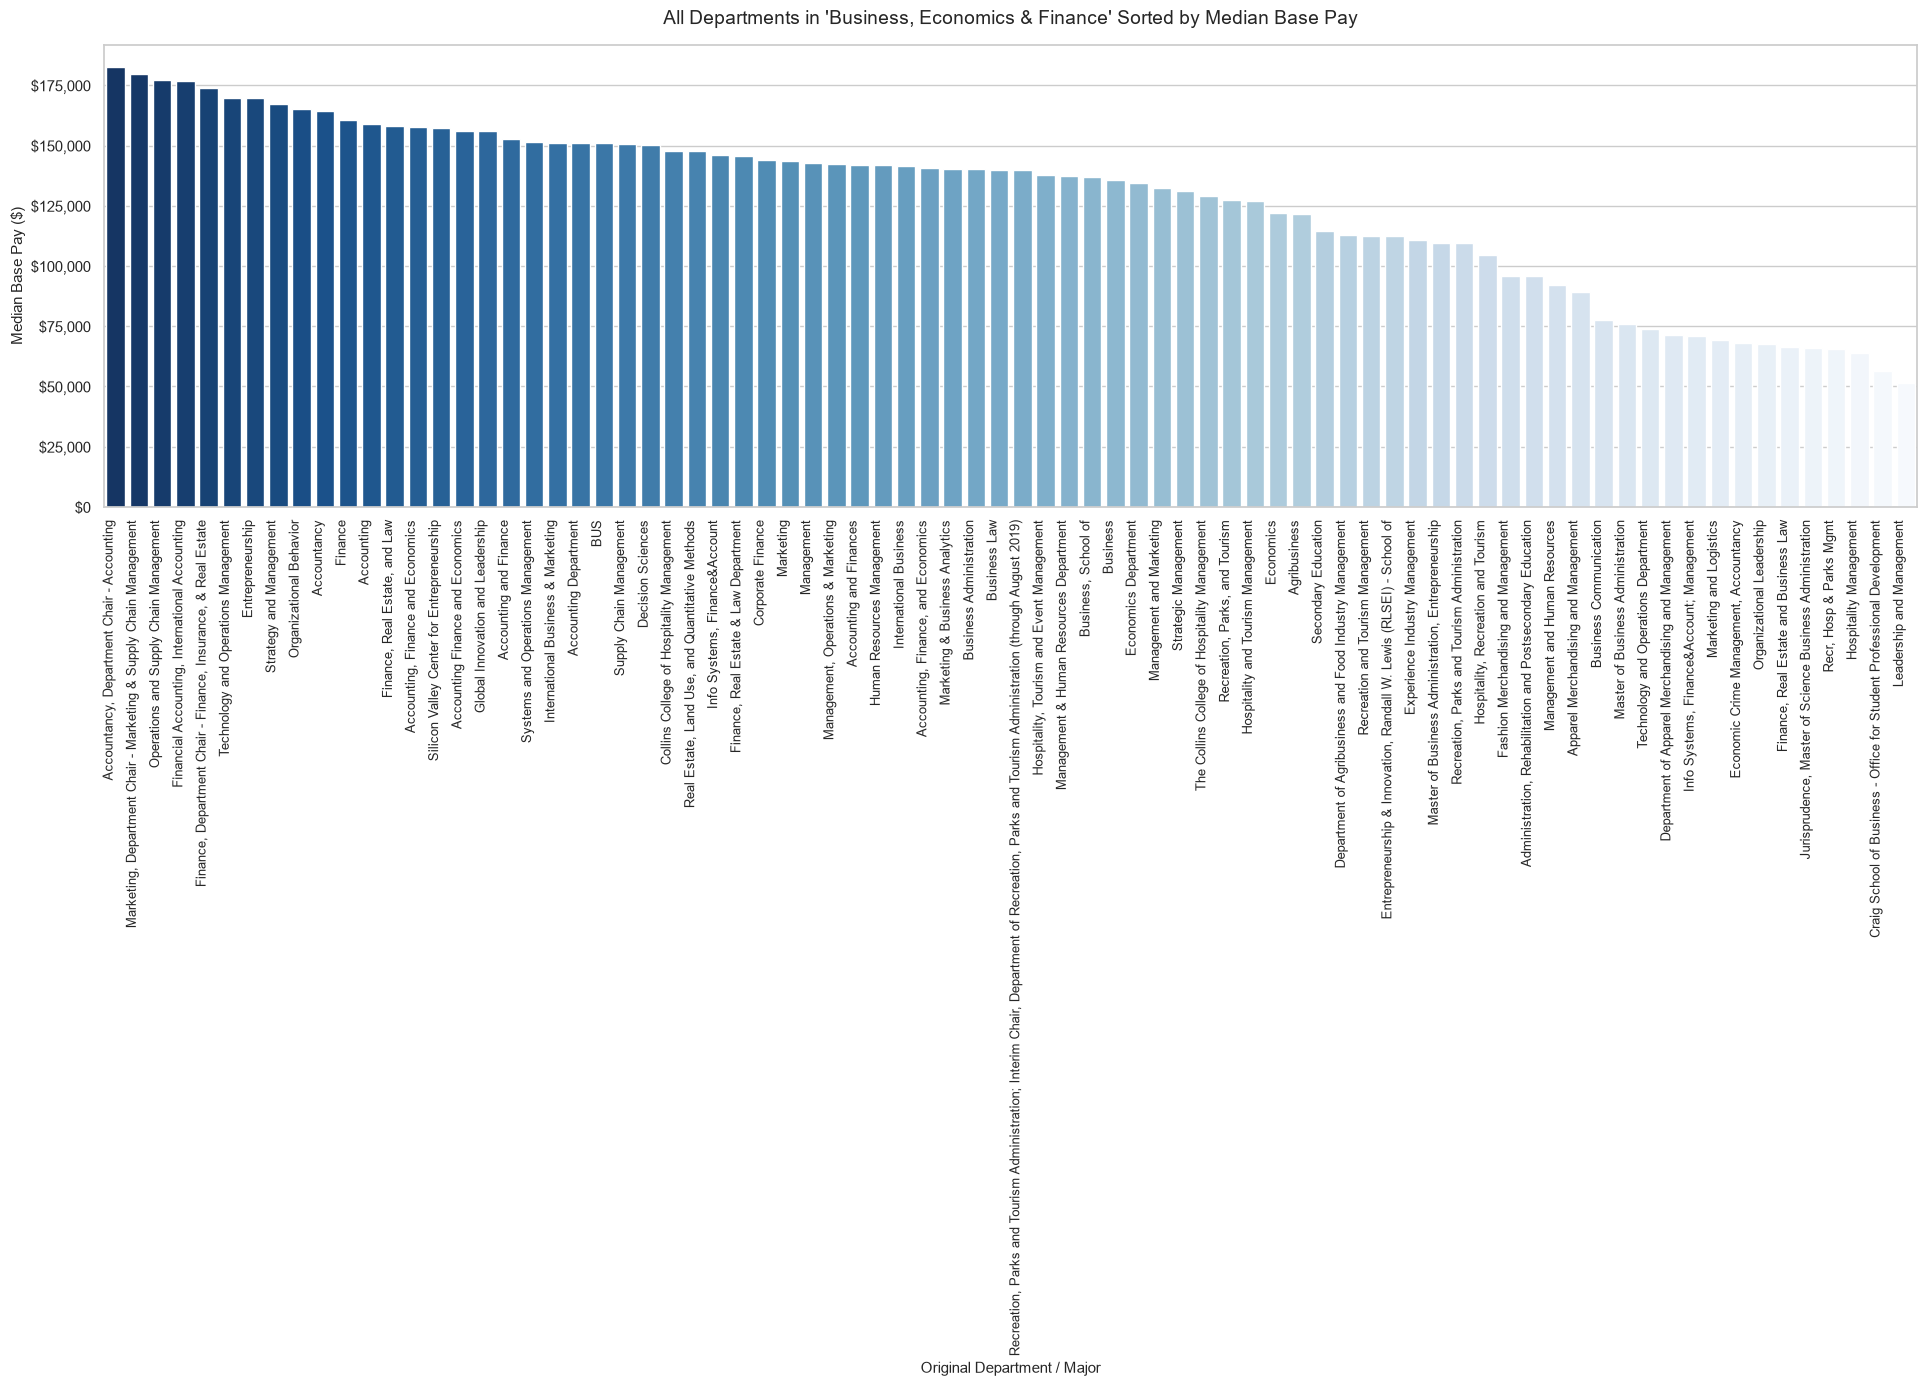

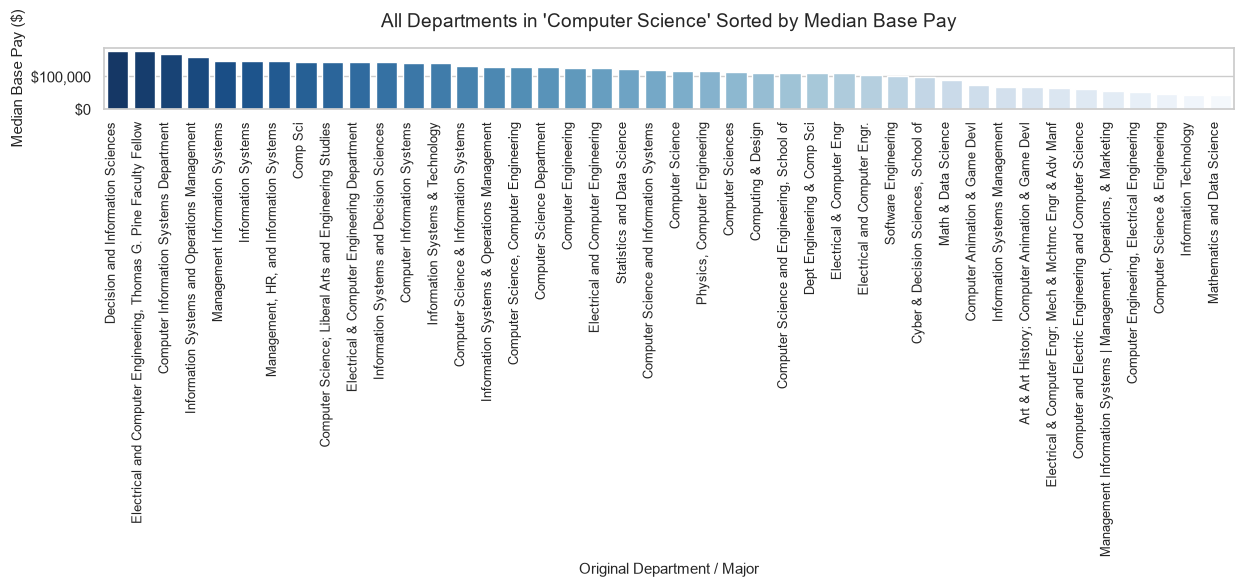

C:\Users\ginny\AppData\Local\Temp\ipykernel_26268\20446149.py:56: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


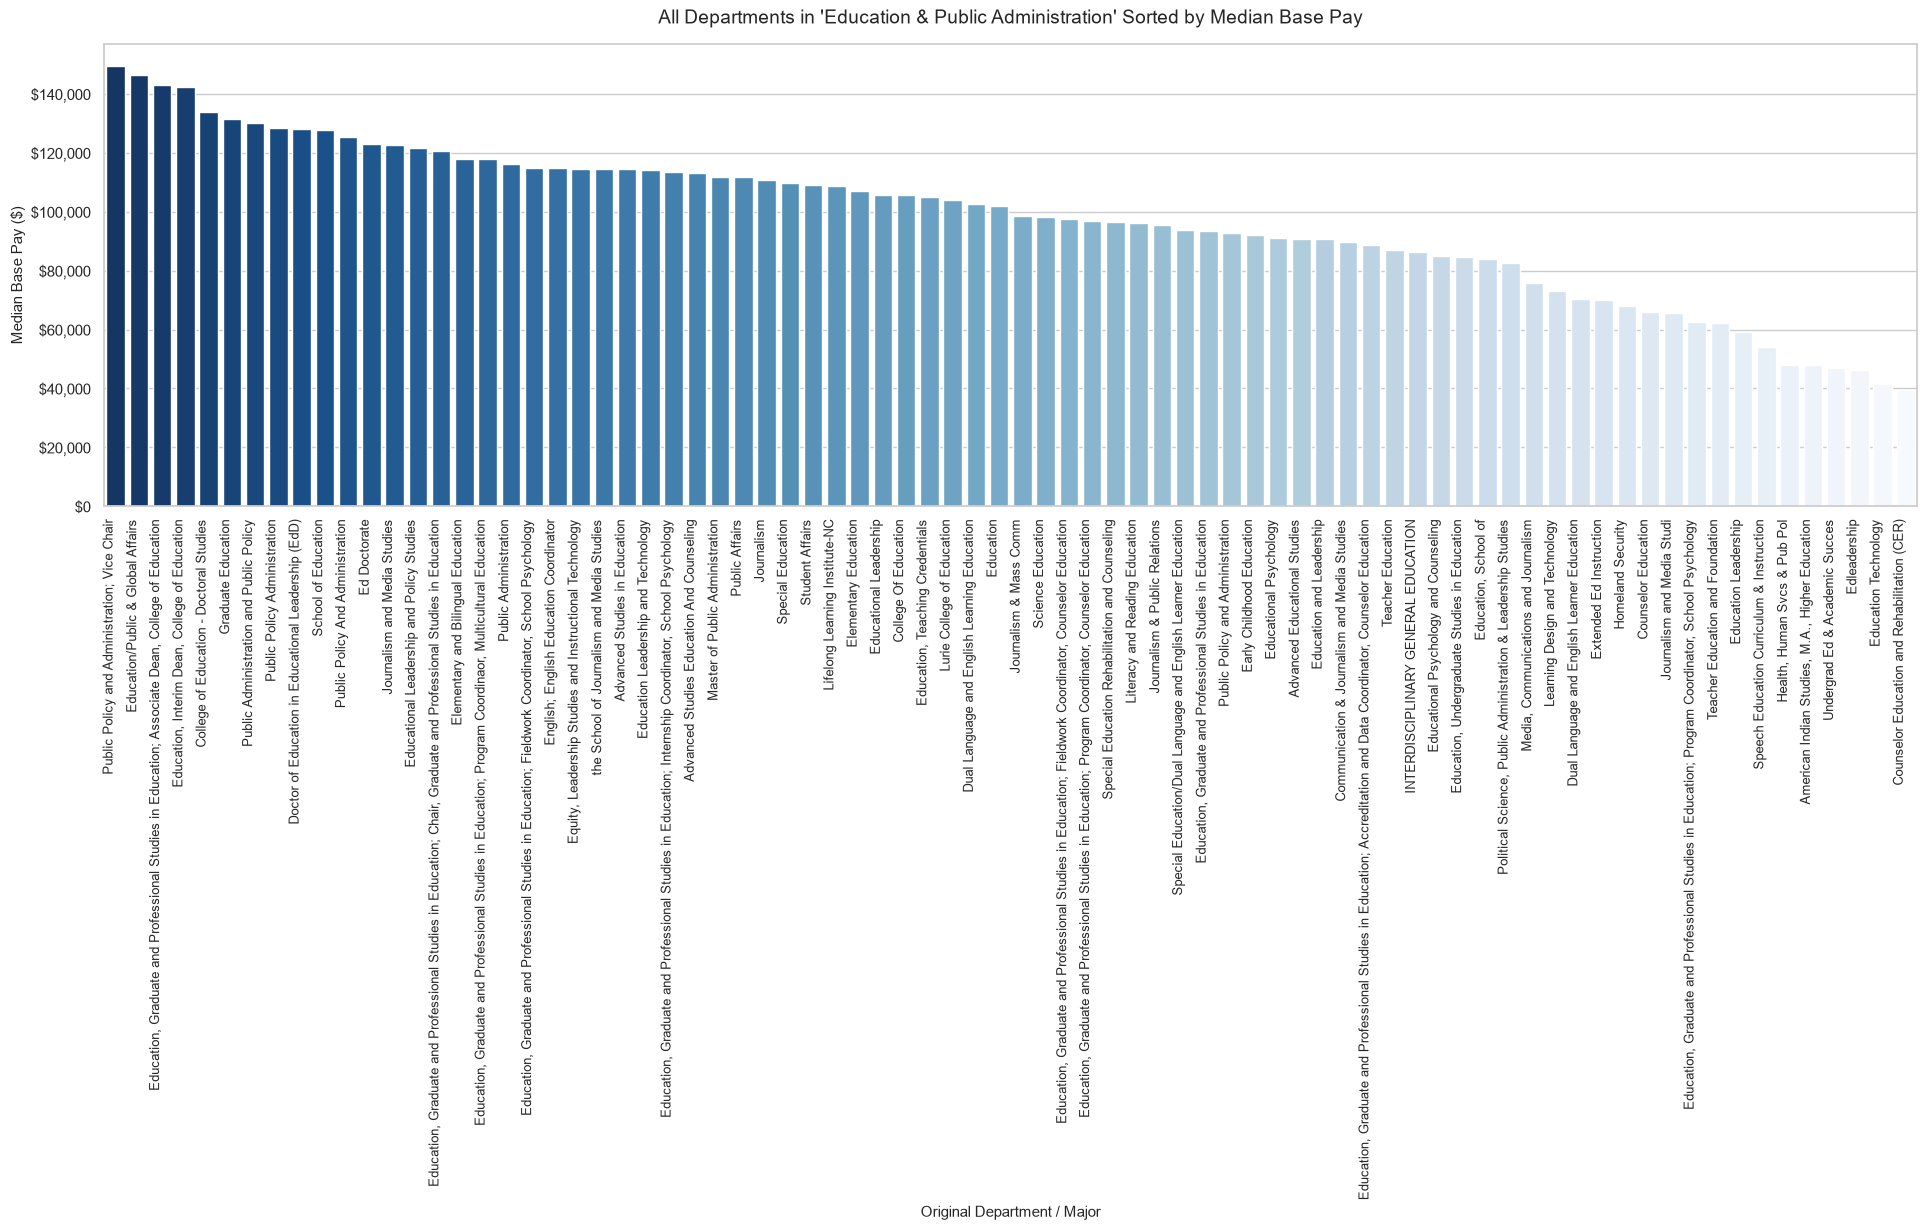

C:\Users\ginny\AppData\Local\Temp\ipykernel_26268\20446149.py:56: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


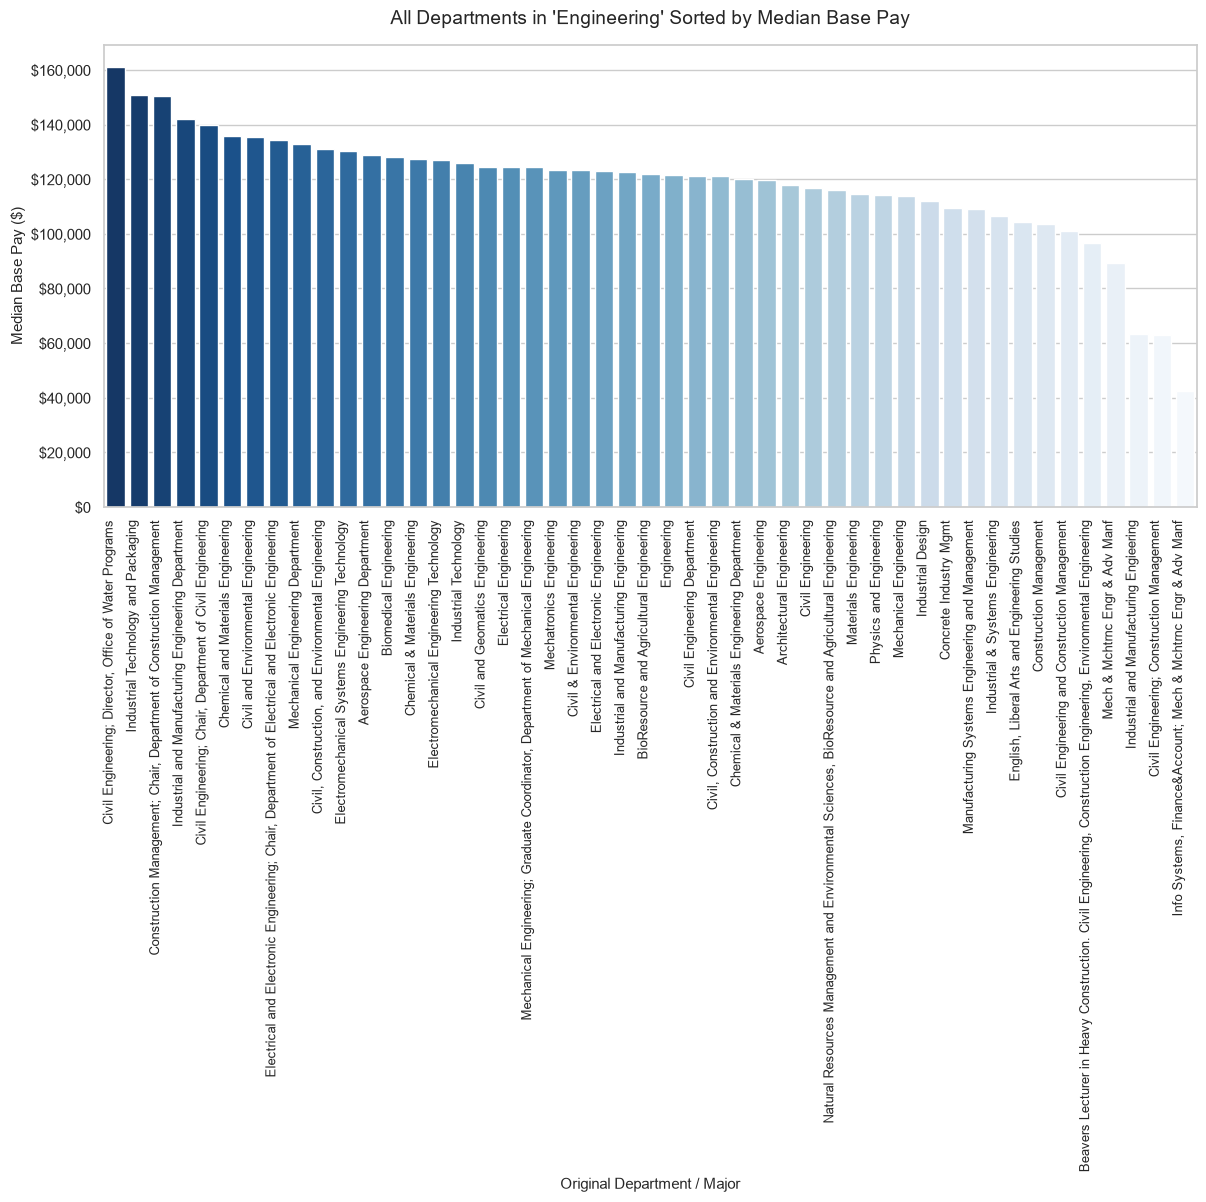

C:\Users\ginny\AppData\Local\Temp\ipykernel_26268\20446149.py:56: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


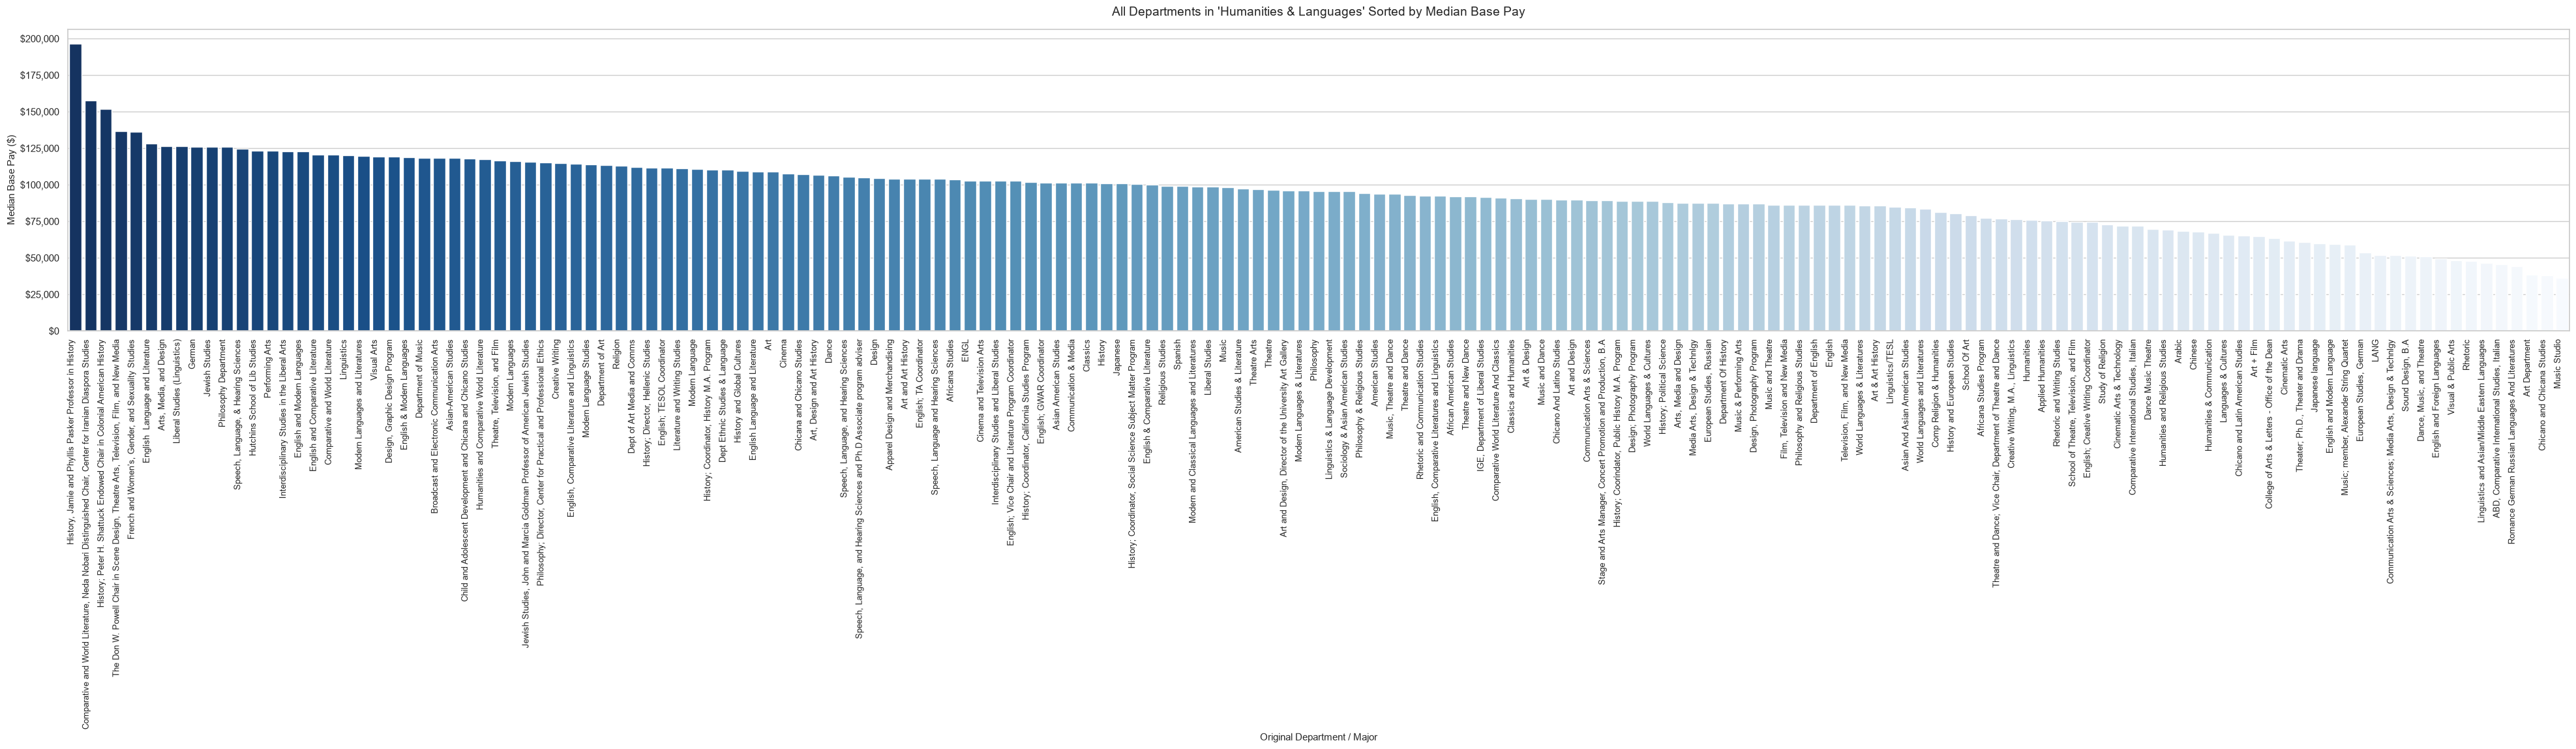

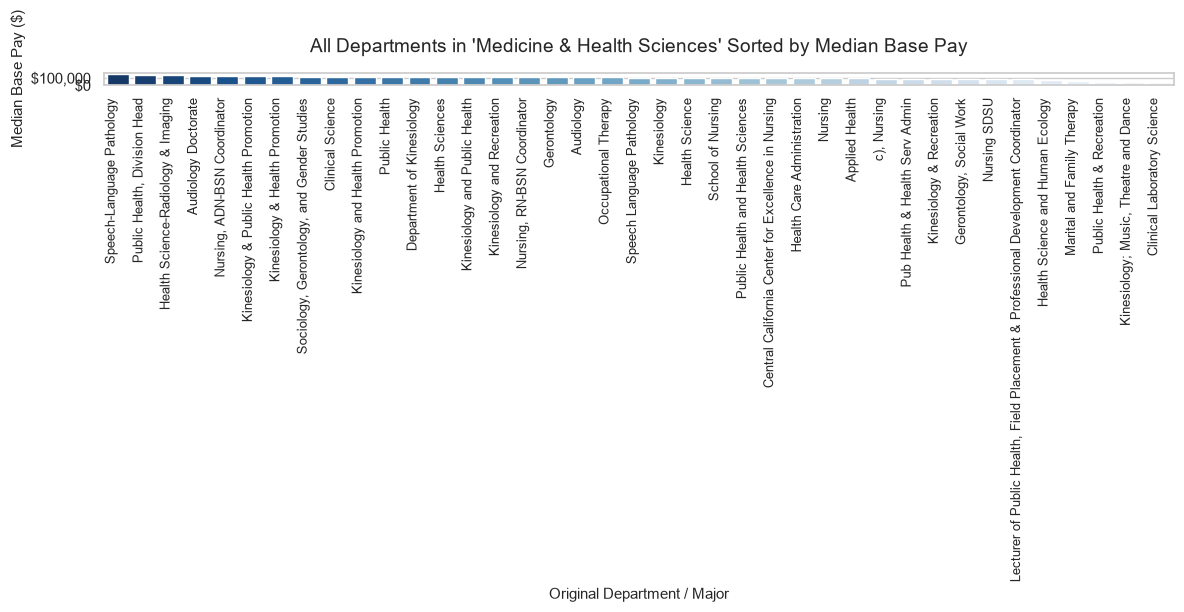

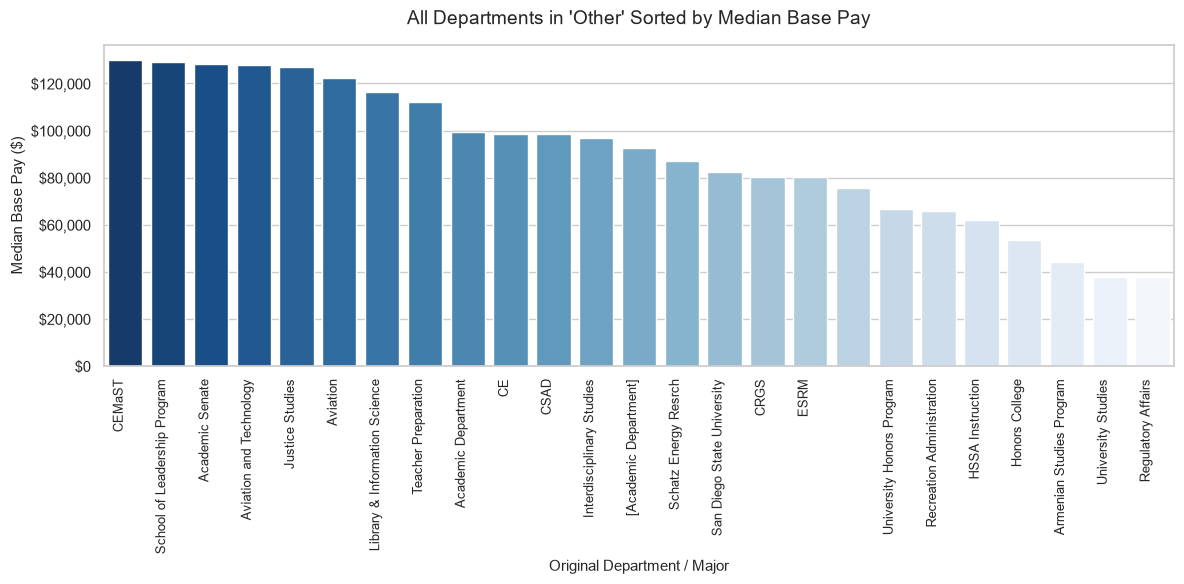

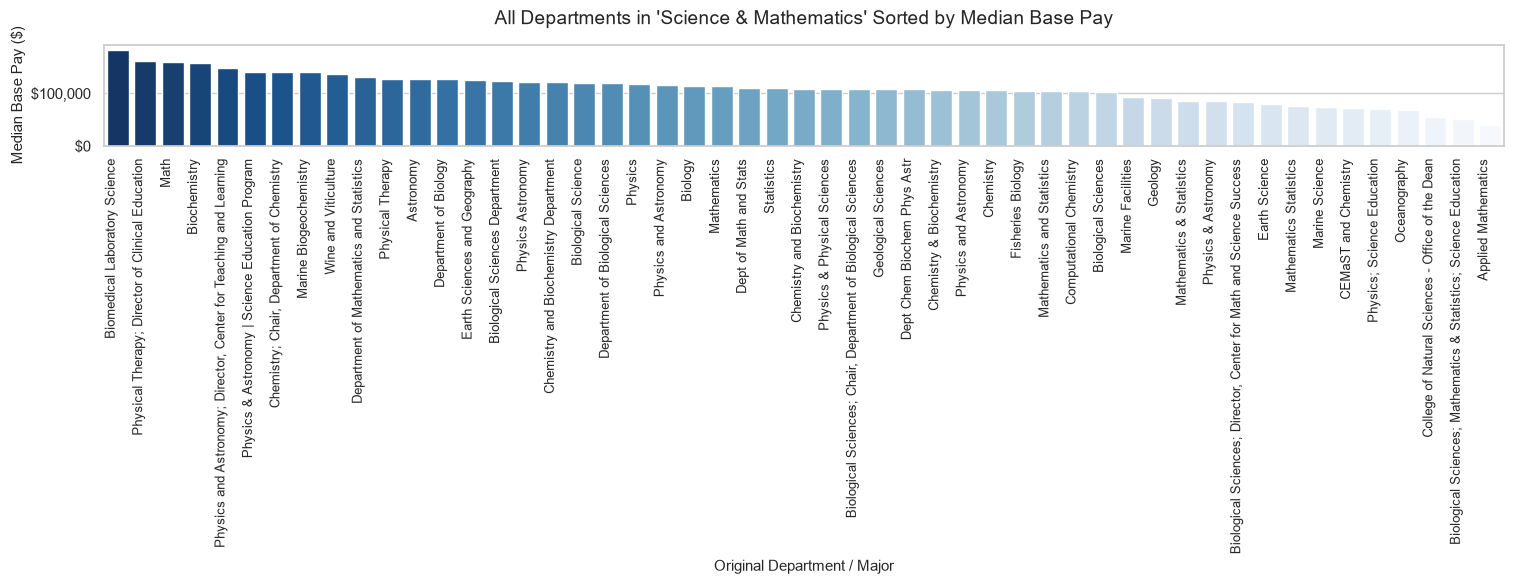

C:\Users\ginny\AppData\Local\Temp\ipykernel_26268\20446149.py:56: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


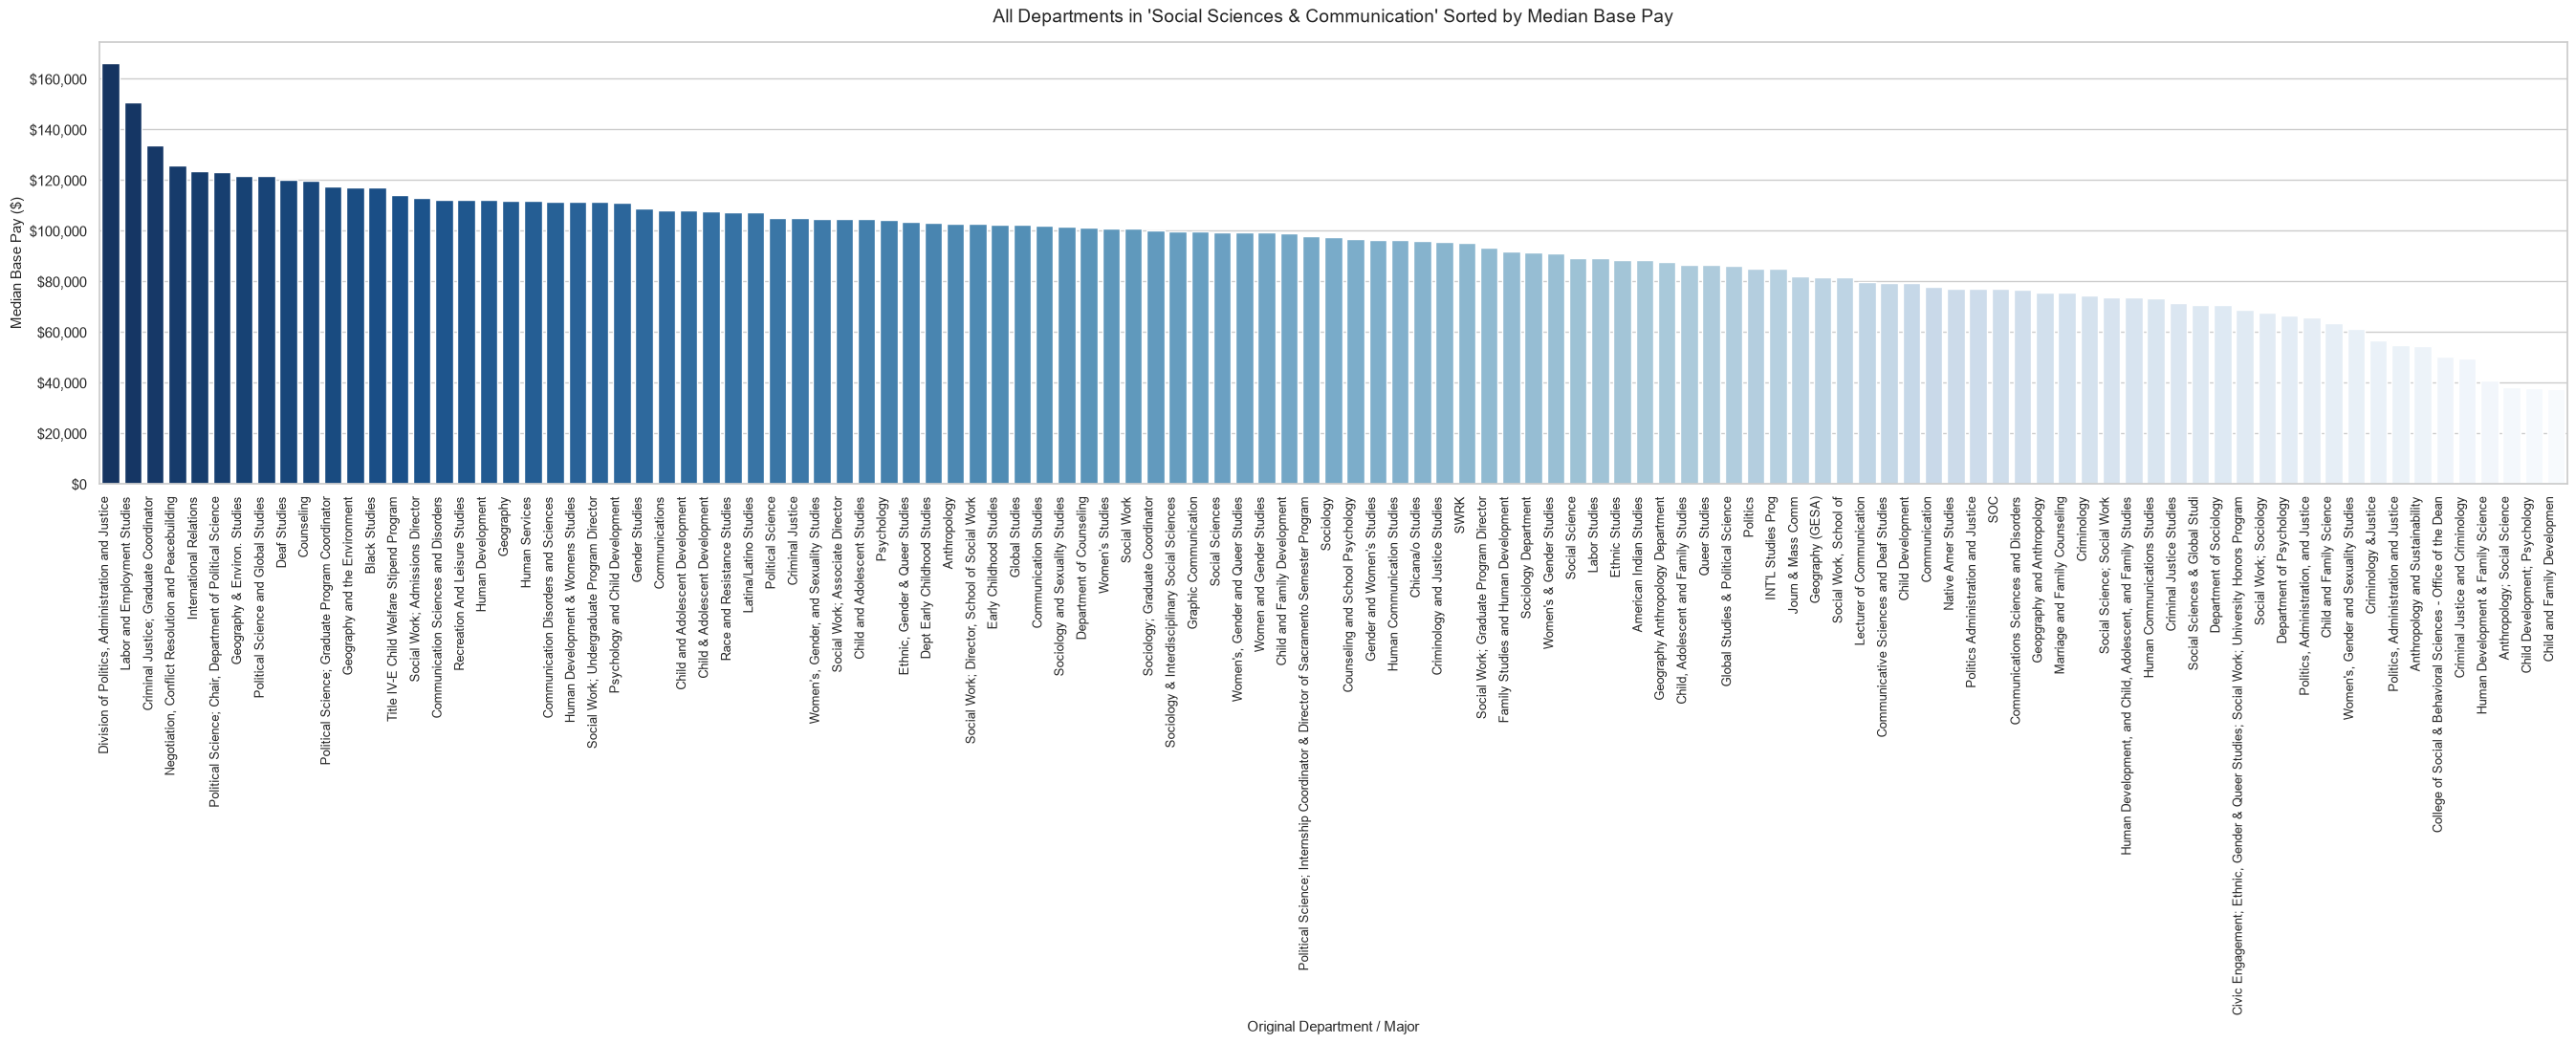

In [37]:
# Graph Generated by Gemni Flash-Lite 2.5

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

df = pd.read_parquet("data/csu_depbucket_cleaned_salaries.parquet")
dept_summary = (
    df.groupby(["department", "original_department"])
    .agg(
        median_base_pay=("base_pay", "median"),
        faculty_count=("base_pay", "count"),
    )
    .reset_index()
)

sns.set_theme(style="whitegrid")
buckets = dept_summary["department"].unique()

for bucket in buckets:
  subset = dept_summary[dept_summary["department"] == bucket].sort_values(
      by="median_base_pay", ascending=False
  )

  if len(subset) == 0:
    continue

  # Dynamically size width based on how many departments are in the bucket
  plt.figure(figsize=(max(12, len(subset) * 0.3), 6))

  ax = sns.barplot(
      data=subset,
      x="original_department",
      y="median_base_pay",
      palette="Blues_r",
      hue="original_department",
      legend=False,
  )

  plt.title(
      f"All Departments in '{bucket}' Sorted by Median Base Pay",
      fontsize=14,
      pad=15,
  )
  plt.xlabel("Original Department / Major", fontsize=11)
  plt.ylabel("Median Base Pay ($)", fontsize=11)

  # Rotate x-tick labels vertically/diagonally for readability
  plt.xticks(rotation=90, ha="right", fontsize=9)

  # Format y-axis with currency commas
  ax.yaxis.set_major_formatter(
      plt.FuncFormatter(lambda y, loc: f"${int(y):,}")
  )

  plt.tight_layout()

  # Save figure
  safe_name = bucket.lower().replace(" & ", "_").replace(" ", "_")
#   plt.savefig(
#       f"data/depts_{safe_name}.png", dpi=300, bbox_inches="tight"
#   )
  plt.show()